# Water body detection from satellite images

This notebook finds rivers, lagoons and ponds in Sentinel-2 satellite images, draws a water map for the dry season
and for the wet season, and shows where water appeared or disappeared.



In [1]:
#@title Your only input: Earth Engine project ID { display-mode: "form" }
# Where to find it: console.cloud.google.com -> click the project name at the top -> copy the value in the ID column.
# It looks like  my-project-123456  (it is NOT the project's display name).
EE_PROJECT_ID = ""  #@param {type:"string"}

## Step 1 · Set up

In [2]:
#@title Set up the project files { display-mode: "form" }
import base64, io, os, pathlib, subprocess, sys, zipfile

IN_COLAB = "google.colab" in sys.modules
PACKAGE_ZIP_B64 = "..."

work = pathlib.Path("/content/waterdet_project") if IN_COLAB else pathlib.Path("waterdet_project").resolve()
if not (work / "config.yaml").exists():
    work.mkdir(parents=True, exist_ok=True)
    zipfile.ZipFile(io.BytesIO(base64.b64decode(PACKAGE_ZIP_B64))).extractall(work)
os.chdir(work)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[gee]"], check=True)
sys.path.insert(0, str(work / "src"))
print("Ready. Working folder:", work)

Ready. Working folder: /content/waterdet_project


In [3]:
import json, logging
from pathlib import Path
from waterdet.config import load_config, validate_config

logging.basicConfig(level=logging.INFO, format="%(message)s")
if not EE_PROJECT_ID.strip():
    raise SystemExit("Type your Earth Engine project ID in the box near the top of the notebook, then run all again.")

cfg = load_config("config.yaml")
cfg["gee"]["project"] = EE_PROJECT_ID.strip()
validate_config(cfg)
print("Study area (west, south, east, north):", cfg["aoi"]["bbox"], "- Lagos lagoon area")
for name, p in cfg["periods"].items():
    print(f"Season '{name}': {p['start']} to {p['end']}")

Study area (west, south, east, north): [3.3, 6.4, 3.55, 6.6] - Lagos lagoon area
Season 'dry': 2025-12-01 to 2026-03-01
Season 'wet': 2026-06-01 to 2026-10-01


## Step 2 · Sign in to Earth Engine
A pop-up asks you to sign in with Google. Approve it.

In [4]:
from waterdet import gee_export as G
from waterdet.config import require_gee_project

G.init_ee(require_gee_project(cfg))
print("Earth Engine is connected.")

Earth Engine is connected.


## Step 3 · Check there are enough satellite images
This only looks; it decides nothing. It stops with a clear message if there are too few images to continue.

In [5]:
from IPython.display import Image, display

counts = G.preflight(cfg)
for period, c in counts.items():
    print(period, c)
tp = cfg["training_period"]
if counts[tp]["after_scene_cloud_filter"] < 3:
    raise SystemExit(f"Only {counts[tp]['after_scene_cloud_filter']} usable satellite images for the {tp} season. "
                     "Copy this message to Claude and it will adjust the dates for you.")
for period in cfg["periods"]:
    print(f"--- true-colour preview: {period} ---")
    display(Image(url=G.preview_url(cfg, period)))

dry {'s2_scenes': 23, 'after_scene_cloud_filter': 16, 'cloud_score_plus_images': 23}
wet {'s2_scenes': 36, 'after_scene_cloud_filter': 2, 'cloud_score_plus_images': 37}
--- true-colour preview: dry ---


--- true-colour preview: wet ---


## Step 4 · Earth Engine prepares the images


In [6]:
import time

tasks = G.start_exports(cfg)
while True:
    status = [t.status() for t in tasks]
    states = [s["state"] for s in status]
    print(time.strftime("%H:%M:%S"), states)
    failed = [s for s in status if s["state"] in ("FAILED", "CANCELLED")]
    if failed:
        raise RuntimeError(f"Export failed: {[s.get('error_message') for s in failed]}.")
    if all(s == "COMPLETED" for s in states):
        break
    time.sleep(30)
print("Earth Engine has finished.")

12:35:21 ['READY', 'READY']
12:35:51 ['RUNNING', 'READY']
12:36:21 ['RUNNING', 'READY']
12:36:52 ['RUNNING', 'RUNNING']
12:37:22 ['RUNNING', 'RUNNING']
12:37:53 ['RUNNING', 'RUNNING']
12:38:23 ['RUNNING', 'RUNNING']
12:38:53 ['RUNNING', 'COMPLETED']
12:39:23 ['COMPLETED', 'COMPLETED']
Earth Engine has finished.


## Step 5 · Copy the prepared images from your Google Drive
A second pop-up asks for Drive access. Approve it.

In [7]:
import shutil, time
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    src_dir = Path("/content/drive/MyDrive") / cfg["gee"]["drive_folder"]
    for period in cfg["periods"]:
        matches = []
        for _ in range(40):                       # Drive can lag a minute or two behind the export
            matches = sorted(src_dir.glob(f"s2_{period}*.tif"), key=lambda f: f.stat().st_mtime)
            if matches:
                break
            time.sleep(15)
        if not matches:
            raise FileNotFoundError(f"No s2_{period}*.tif in {src_dir}. ")
        if any("-0000" in m.name for m in matches):
            raise RuntimeError(f"The {period} export was split into tiles.")
        shutil.copy(matches[-1], DATA / f"s2_{period}.tif")      # newest file if you have run this before
        print("copied", matches[-1].name)
else:
    print("Not on Colab: put s2_<season>.tif from your Drive folder into the data/ folder.")
    print("Present now:", sorted(p.name for p in DATA.glob("s2_*.tif")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
copied s2_dry.tif
copied s2_wet.tif


In [28]:
from pathlib import Path

Path("data/reference_points.csv").unlink(missing_ok=True)
Path("data/reference_points.meta.json").unlink(missing_ok=True)
print("Removed. Now re-run Step 6, then Step 7, then your Step 8 cell.")

Removed. Now re-run Step 6, then Step 7, then your Step 8 cell.


In [29]:
import copy, time, shutil
from pathlib import Path
from google.colab import drive
from waterdet.config import validate_config

# Settings that give the rainy season a fair chance
cfg["imagery"]["max_scene_cloud_pct"] = 90
cfg["imagery"]["min_valid_obs"] = 2
cfg["periods"]["wet"] = {"start": "2026-05-01", "end": "2026-10-17"}
validate_config(cfg)
print("Wet-season scene counts:", G.preflight(cfg)["wet"])

# Re-export the wet season only
cfg_wet = copy.deepcopy(cfg)
cfg_wet["periods"] = {"wet": cfg["periods"]["wet"]}
tasks = G.start_exports(cfg_wet)
while True:
    states = [t.status()["state"] for t in tasks]
    print(time.strftime("%H:%M:%S"), states)
    if any(s in ("FAILED", "CANCELLED") for s in states):
        raise RuntimeError([t.status().get("error_message") for t in tasks])
    if all(s == "COMPLETED" for s in states):
        break
    time.sleep(30)

# Copy the newest wet file from Drive
drive.mount("/content/drive")
folder = Path("/content/drive/MyDrive") / cfg["gee"]["drive_folder"]
for attempt in range(6):
    files = sorted(folder.glob("s2_wet*.tif"), key=lambda f: f.stat().st_mtime)
    if files:
        break
    drive.flush_and_unmount(); drive.mount("/content/drive", force_remount=True); time.sleep(20)
shutil.copy(files[-1], "data/s2_wet.tif")
print("Copied", files[-1].name, "->", "data/s2_wet.tif")

Wet-season scene counts: {'s2_scenes': 51, 'after_scene_cloud_filter': 23, 'cloud_score_plus_images': 52}
14:31:15 ['READY']
14:31:45 ['RUNNING']
14:32:15 ['RUNNING']
14:32:46 ['RUNNING']
14:33:16 ['RUNNING']
14:33:46 ['RUNNING']
14:34:16 ['RUNNING']
14:34:46 ['COMPLETED']
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied s2_wet (1).tif -> data/s2_wet.tif


## Step 6 · Train the model and make the maps
The computer learns what water looks like, tests itself on areas it has not seen, compares itself against simple
water-index thresholds, and draws the maps.

In [33]:
from waterdet import pipeline

summary = pipeline.run(cfg, data_dir="data", out_dir="outputs")
for n in summary["notes"]:
    print("NOTE:", n)

NOTE: No independent reference points found at data/reference_points.csv. Accuracy above is agreement with JRC-derived labels only. Optional: docs/OPTIONAL_ACCURACY_CHECK.md explains how to get a true accuracy figure.


## Step 7 · Your results

# waterdet results

## Label mode `gsw` (training period `dry`)

- Tree: depth 2, 4 leaves, params {'max_depth': 2, 'min_samples_leaf': 50}
- Points: 6954 train / 3046 test (116 / 52 spatial blocks)
- Train overall accuracy: 0.9810 (shown only to expose over-fitting)

| Method (spatial hold-out) | Overall acc. [95% CI] | Kappa [95% CI] | Water F1 | Water IoU |
|---|---|---|---|---|
| **Decision Tree** | 0.9852 [0.969, 0.995] | 0.9704 [0.936, 0.990] | 0.9855 | 0.9714 |
| NDWI>0 (thr 0.000) | 0.9734 | 0.9468 | 0.9742 | 0.9496 |
| MNDWI>0 (thr 0.000) | 0.9839 | 0.9678 | 0.9842 | 0.9689 |
| NDWI Otsu (thr 0.012) | 0.9770 | 0.9540 | 0.9776 | 0.9561 |
| MNDWI Otsu (thr 0.066) | 0.9879 | 0.9757 | 0.9880 | 0.9763 |

_These scores measure agreement with JRC-derived labels on held-out spatial blocks, using a class-balanced 50:50 sample. They are NOT independent truth, and water precision / F1 / IoU change with the class ratio. Use the area-weighted reference validation below for headline numbers._

## Label mode `gsw_dw` (training period `dry`)

- Tree: depth 2, 3 leaves, params {'max_depth': 2, 'min_samples_leaf': 1}
- Points: 6974 train / 3026 test (121 / 46 spatial blocks)
- Train overall accuracy: 0.9996 (shown only to expose over-fitting)

| Method (spatial hold-out) | Overall acc. [95% CI] | Kappa [95% CI] | Water F1 | Water IoU |
|---|---|---|---|---|
| **Decision Tree** | 0.9960 [0.992, 0.999] | 0.9921 [0.984, 0.998] | 0.9960 | 0.9921 |
| NDWI>0 (thr 0.000) | 0.9815 | 0.9630 | 0.9817 | 0.9640 |
| MNDWI>0 (thr 0.000) | 0.9937 | 0.9874 | 0.9937 | 0.9875 |
| NDWI Otsu (thr 0.012) | 0.9874 | 0.9749 | 0.9875 | 0.9753 |
| MNDWI Otsu (thr 0.066) | 0.9967 | 0.9934 | 0.9967 | 0.9934 |

_These scores measure agreement with JRC-derived labels on held-out spatial blocks, using a class-balanced 50:50 sample. They are NOT independent truth, and water precision / F1 / IoU change with the class ratio. Use the area-weighted reference validation below for headline numbers._

## Water extent (primary model)

| Period | Water km² | Land km² | No data % |
|---|---|---|---|
| dry | 230.10 | 381.56 | 0.2 |
| wet | 236.88 | 375.34 | 0.1 |

### Change dry_to_wet

- stable land: 370.64 km²
- stable water: 226.27 km²
- water gain (land -> water): 10.56 km²
- water loss (water -> land): 3.80 km²
- compared_km2: 611.27 km²

## Notes and warnings

- No independent reference points found at data/reference_points.csv. Accuracy above is agreement with JRC-derived labels only. Optional: docs/OPTIONAL_ACCURACY_CHECK.md explains how to get a true accuracy figure.

## Provenance

- Python 3.13.16; packages: waterdet 0.1.0, numpy 2.1.3, scipy 1.16.3, pandas 2.2.3, scikit-learn 1.6.1, rasterio 1.5.2, earthengine-api 1.7.39
- Input `s2_dry.tif` sha256 `1779b694527fe1f9…`
- Input `s2_wet.tif` sha256 `eeef3e335953aa7d…`
- Full config snapshot (GEE project id redacted) is in `summary.json`.


outputs/maps/change_dry_to_wet.png


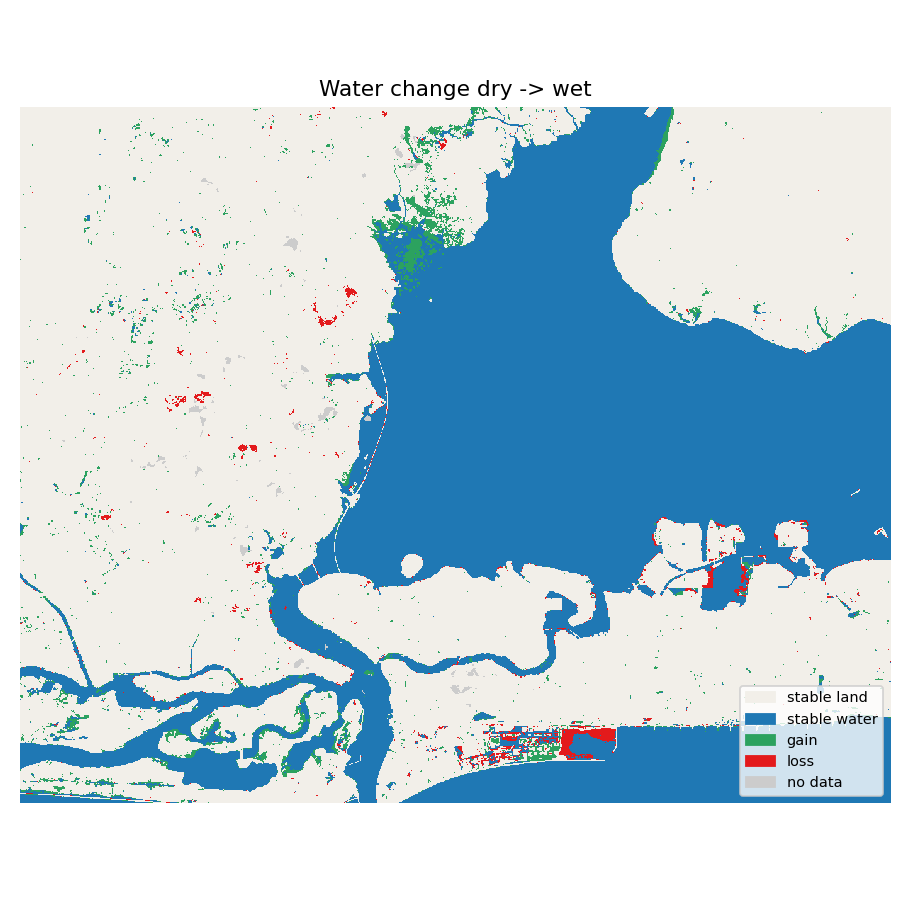

outputs/maps/water_dry.png


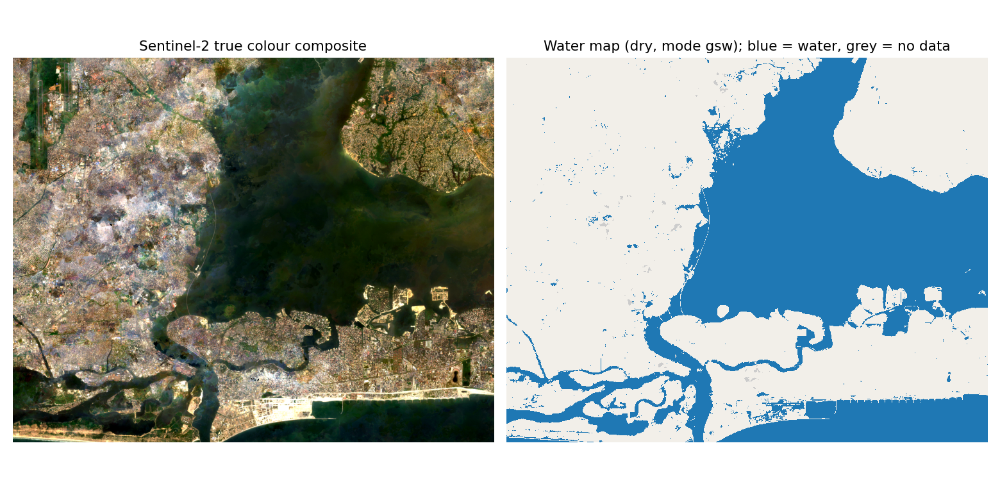

outputs/maps/water_wet.png


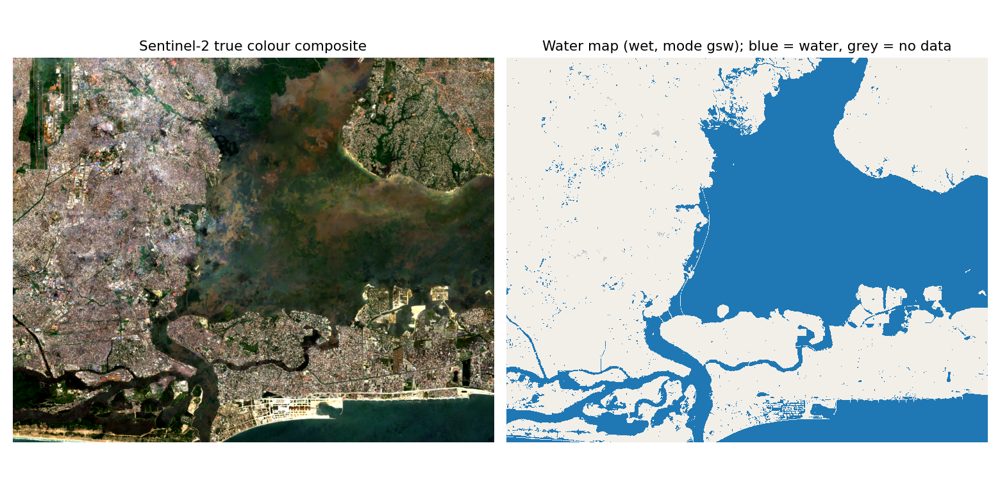

outputs/mode_gsw/cv_depth_curve.png


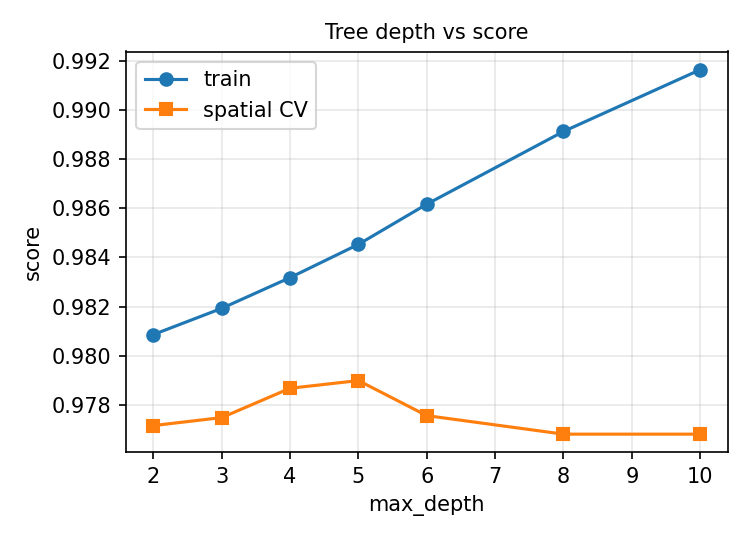

outputs/mode_gsw/tree.png


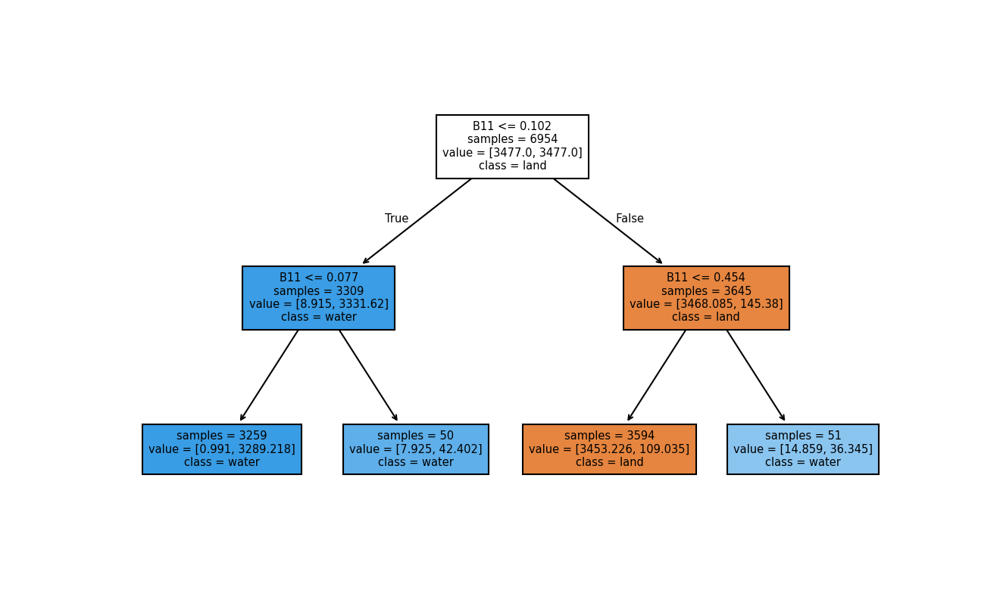

|--- B11 <= 0.10
|   |--- B11 <= 0.08
|   |   |--- weights: [0.99, 3289.22] class: 1
|   |--- B11 >  0.08
|   |   |--- weights: [7.92, 42.40] class: 1
|--- B11 >  0.10
|   |--- B11 <= 0.45
|   |   |--- weights: [3453.23, 109.03] class: 0
|   |--- B11 >  0.45
|   |   |--- weights: [14.86, 36.34] class: 1



In [34]:
from IPython.display import Markdown, display, Image

display(Markdown(Path("outputs/summary.md").read_text(encoding="utf-8")))
mode = cfg["labels"]["primary_mode"]
for f in sorted(Path("outputs/maps").glob("*.png")) + [Path(f"outputs/mode_{mode}") / n for n in ("cv_depth_curve.png", "tree.png")]:
    if Path(f).exists():
        print(f)
        display(Image(filename=str(f)))
print(Path(f"outputs/mode_{mode}/tree_rules.txt").read_text(encoding="utf-8"))

## Step 8 · Presentation pack and app data
Makes slide-ready images (the satellite image, the data the model sees, the detection, the change map, the decision tree,
the key numbers) in `outputs/presentation/`, and the small files for the Streamlit app in `outputs/streamlit_data/`.

Slide images:
  01_satellite_dry.png
  01_satellite_wet.png
  02_detection_dry.png
  02_detection_wet.png
  03_before_after_dry.png
  03_before_after_wet.png
  04_model_inputs_dry.png
  05_change_map.png
  06_dry_wet_change.png
  07_key_numbers.png
  08_decision_tree.png
  08_decision_tree_rules.txt
  09_depth_choice.png
  10_confusion_matrix.png
  11_feature_importance.png
  README_presentation.md
  key_numbers.csv


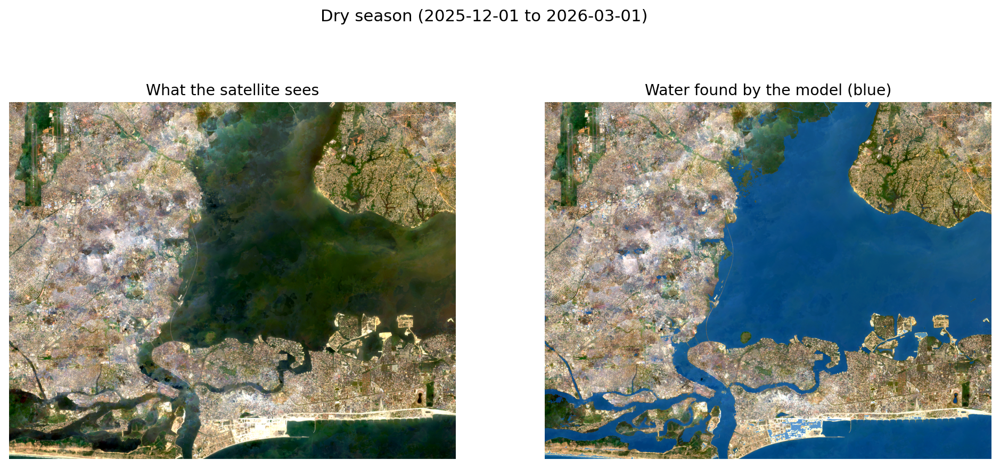

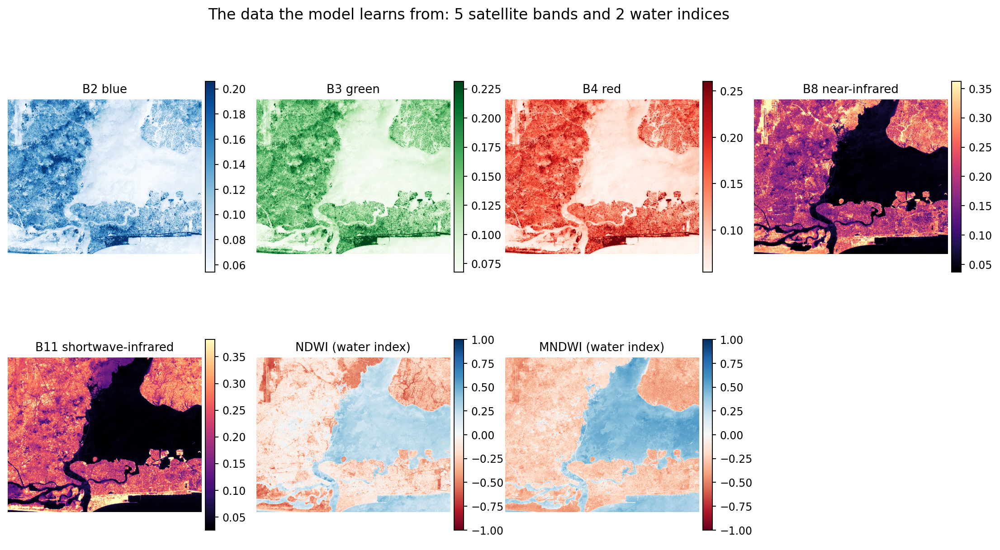

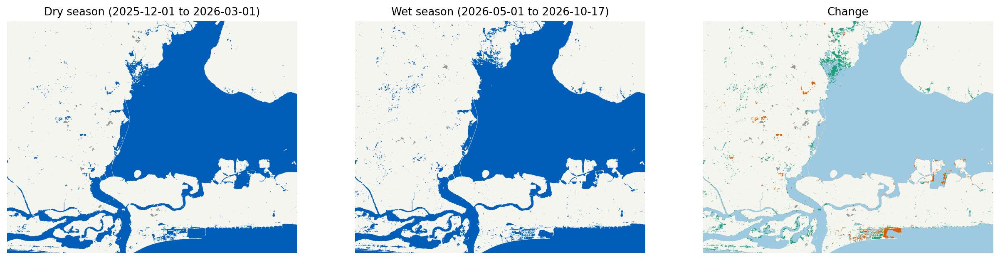

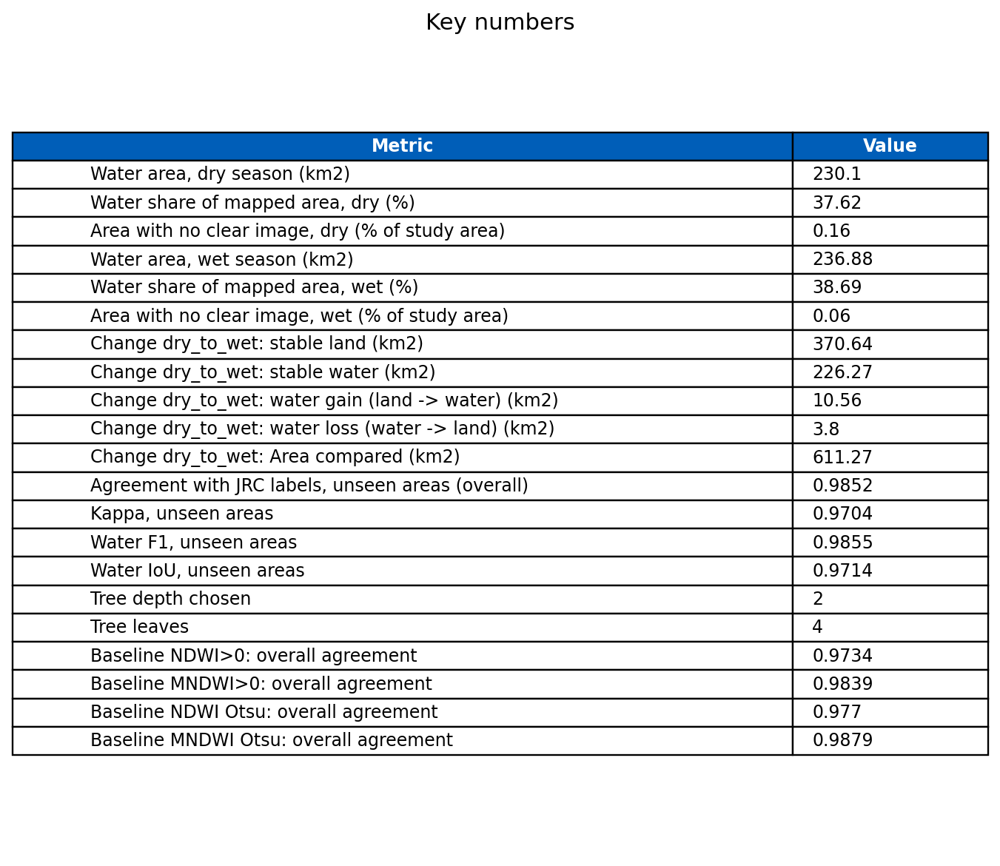

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
from waterdet.presentation import build_presentation_pack

pack = build_presentation_pack(cfg, data_dir="data", out_dir="outputs")
print("Slide images:", *pack["files"]["presentation"], sep="\n  ")
for f in ("03_before_after_dry.png", "04_model_inputs_dry.png", "06_dry_wet_change.png", "07_key_numbers.png"):
    p = Path(pack["presentation_dir"]) / f
    if p.exists():
        display(Image(filename=str(p)))
shutil.make_archive("waterdet_presentation", "zip", "outputs")
if IN_COLAB:
    from google.colab import files
    files.download("waterdet_presentation.zip")

## Step 9 · Download everything

In [36]:
shutil.make_archive("waterdet_results", "zip", "outputs")
print("Wrote waterdet_results.zip")
if IN_COLAB:
    from google.colab import files
    files.download("waterdet_results.zip")

Wrote waterdet_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Optional, later: get a true accuracy number
You do not need this to finish the project. The numbers above measure agreement with a global water map (JRC), which
is useful but is not proof the map matches reality. If you later want a true accuracy figure, label about 200 points by
looking at satellite images. The steps are in `docs/OPTIONAL_ACCURACY_CHECK.md`. The two cells below are for that.

In [26]:
frame = Path("outputs/reference_frame")
frozen = Path("data/reference_points.meta.json")
if frozen.exists():
    print("Frame already frozen, not overwritten:", frozen)
else:
    shutil.copy(frame / "reference_frame.meta.json", frozen)
    print("Frozen:", frozen)
print("Label the CSV from this frame:", frame / "reference_frame.csv")
if IN_COLAB:
    from google.colab import files
    files.download(str(frame / "reference_frame.csv"))
    files.download(str(frame / "reference_frame.kml"))

Frozen: data/reference_points.meta.json
Label the CSV from this frame: outputs/reference_frame/reference_frame.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
# After labelling, upload the finished CSV, then re-run Steps 6 and 7.
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    assert len(uploaded) == 1, "Upload exactly one file"
    shutil.move(next(iter(uploaded)), "data/reference_points.csv")
print("Reference CSV present:", Path("data/reference_points.csv").exists())

Saving reference_frame.csv to reference_frame.csv
Reference CSV present: True
